# TLB Risk Prediction using Weather Data (Nepal)

Late blight (TLB) is a big problem for potato and tomato farmers in Nepal. It spreads fast when the
weather is very humid and the nights are cold. In this notebook I am trying to predict if tomorrow will
have weather that is good for the disease, using daily weather data of 62 districts from 1981 to 2019.

What I do in this notebook:
1. load the data and do some EDA
2. make date and season columns
3. make the TLB label
4. feature engineering
5. split the data by year
6. baseline models
7. RF, XGBoost and CatBoost
8. tuning XGBoost
9. compare all models
10. feature importance and SHAP
11. risk by district and season

**Why I redid this:** In my first notebook every model got around 0.99. The problem was that I made
the label using RH_2m and MinTemp_2m of the same day, and RH_2m was also one of the features. So the
model was just learning my own rule. Here I predict the next day instead, split the data by year, and
fit the scaler and class weights only on training data.

# **Importing Libraries**

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             roc_curve, precision_recall_curve)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import shap
import joblib

sns.set_style("whitegrid")

In [2]:
# folder for saving plots and results
os.makedirs("outputs", exist_ok=True)

# **Loading the dataset**

In [3]:
df = pd.read_csv("data/dailyweather.csv")
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (883128, 23)
Columns: ['Unnamed: 0', 'Date', 'District', 'Latitude', 'Longitude', 'Precip', 'Pressure', 'Humidity_2m', 'RH_2m', 'Temp_2m', 'WetBulbTemp_2m', 'MaxTemp_2m', 'MinTemp_2m', 'TempRange_2m', 'EarthSkinTemp', 'WindSpeed_10m', 'MaxWindSpeed_10m', 'MinWindSpeed_10m', 'WindSpeedRange_10m', 'WindSpeed_50m', 'MaxWindSpeed_50m', 'MinWindSpeed_50m', 'WindSpeedRange_50m']


In [4]:
df.head()

,Unnamed: 0,Date,District,Latitude,Longitude,Precip,Pressure,Humidity_2m,RH_2m,Temp_2m,...,TempRange_2m,EarthSkinTemp,WindSpeed_10m,MaxWindSpeed_10m,MinWindSpeed_10m,WindSpeedRange_10m,WindSpeed_50m,MaxWindSpeed_50m,MinWindSpeed_50m,WindSpeedRange_50m
0,0,1981-01-01,Arghakhanchi,27.9,83.2,0.00,93.51,4.81,45.41,13.89,...,10.89,11.32,1.89,3.83,0.69,3.14,2.41,4.12,0.73,3.39
1,1,1981-01-02,Arghakhanchi,27.9,83.2,0.00,93.59,4.94,46.78,13.84,...,11.17,11.44,1.72,2.60,1.09,1.50,2.25,3.30,0.96,2.34
2,2,1981-01-03,Arghakhanchi,27.9,83.2,0.03,93.55,5.22,47.91,14.33,...,9.93,12.24,1.80,2.80,0.48,2.32,2.32,3.54,0.39,3.15
3,3,1981-01-04,Arghakhanchi,27.9,83.2,0.02,93.49,5.36,50.83,13.82,...,10.41,12.17,2.18,3.54,1.06,2.49,2.90,4.05,0.93,3.12
4,4,1981-01-05,Arghakhanchi,27.9,83.2,1.84,93.49,5.84,55.55,13.76,...,10.53,12.32,1.96,2.70,0.69,2.02,2.74,4.64,0.96,3.68


In [5]:
# first column is just the old index, dont need it
df = df.drop(columns=["Unnamed: 0"])

# **EDA**

In [6]:
# structure, dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 883128 entries, 0 to 883127
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                883128 non-null  str    
 1   District            883128 non-null  str    
 2   Latitude            883128 non-null  float64
 3   Longitude           883128 non-null  float64
 4   Precip              883128 non-null  float64
 5   Pressure            883128 non-null  float64
 6   Humidity_2m         883128 non-null  float64
 7   RH_2m               883128 non-null  float64
 8   Temp_2m             883128 non-null  float64
 9   WetBulbTemp_2m      883128 non-null  float64
 10  MaxTemp_2m          883128 non-null  float64
 11  MinTemp_2m          883128 non-null  float64
 12  TempRange_2m        883128 non-null  float64
 13  EarthSkinTemp       883128 non-null  float64
 14  WindSpeed_10m       883128 non-null  float64
 15  MaxWindSpeed_10m    883128 non-null  float64


In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Latitude,883128.0,27.96,0.88,26.50,27.30,27.95,28.50,30.00
Longitude,883128.0,84.28,2.18,80.20,82.40,84.30,85.90,87.90
Precip,883128.0,2.43,6.16,0.00,0.00,0.05,1.87,177.79
Pressure,883128.0,82.90,10.71,54.73,77.68,83.72,92.74,100.34
Humidity_2m,883128.0,8.49,5.43,0.27,3.91,6.75,13.17,23.27
RH_2m,883128.0,55.66,22.88,4.04,36.54,54.32,77.16,100.00
Temp_2m,883128.0,15.82,9.17,-25.44,10.07,16.73,22.50,38.61
WetBulbTemp_2m,883128.0,5.43,10.85,-28.19,-2.74,4.98,14.78,27.15
MaxTemp_2m,883128.0,21.86,8.85,-16.94,16.55,22.51,27.94,46.82
MinTemp_2m,883128.0,11.06,9.35,-37.24,5.41,11.98,17.91,32.77


In [8]:
df["District"].nunique()

62

In [9]:
#checking missing values
print(df.isnull().sum())

Date                  0
District              0
Latitude              0
Longitude             0
Precip                0
Pressure              0
Humidity_2m           0
RH_2m                 0
Temp_2m               0
WetBulbTemp_2m        0
MaxTemp_2m            0
MinTemp_2m            0
TempRange_2m          0
EarthSkinTemp         0
WindSpeed_10m         0
MaxWindSpeed_10m      0
MinWindSpeed_10m      0
WindSpeedRange_10m    0
WindSpeed_50m         0
MaxWindSpeed_50m      0
MinWindSpeed_50m      0
WindSpeedRange_50m    0
dtype: int64


In [10]:
# any duplicate day for same district?
print("Duplicates:", df.duplicated(subset=["District", "Date"]).sum())

# days per district
print(df["District"].value_counts().head())

Duplicates: 0
District
Arghakhanchi    14244
Baglung         14244
Baitadi         14244
Bajang          14244
Banke           14244
Name: count, dtype: int64


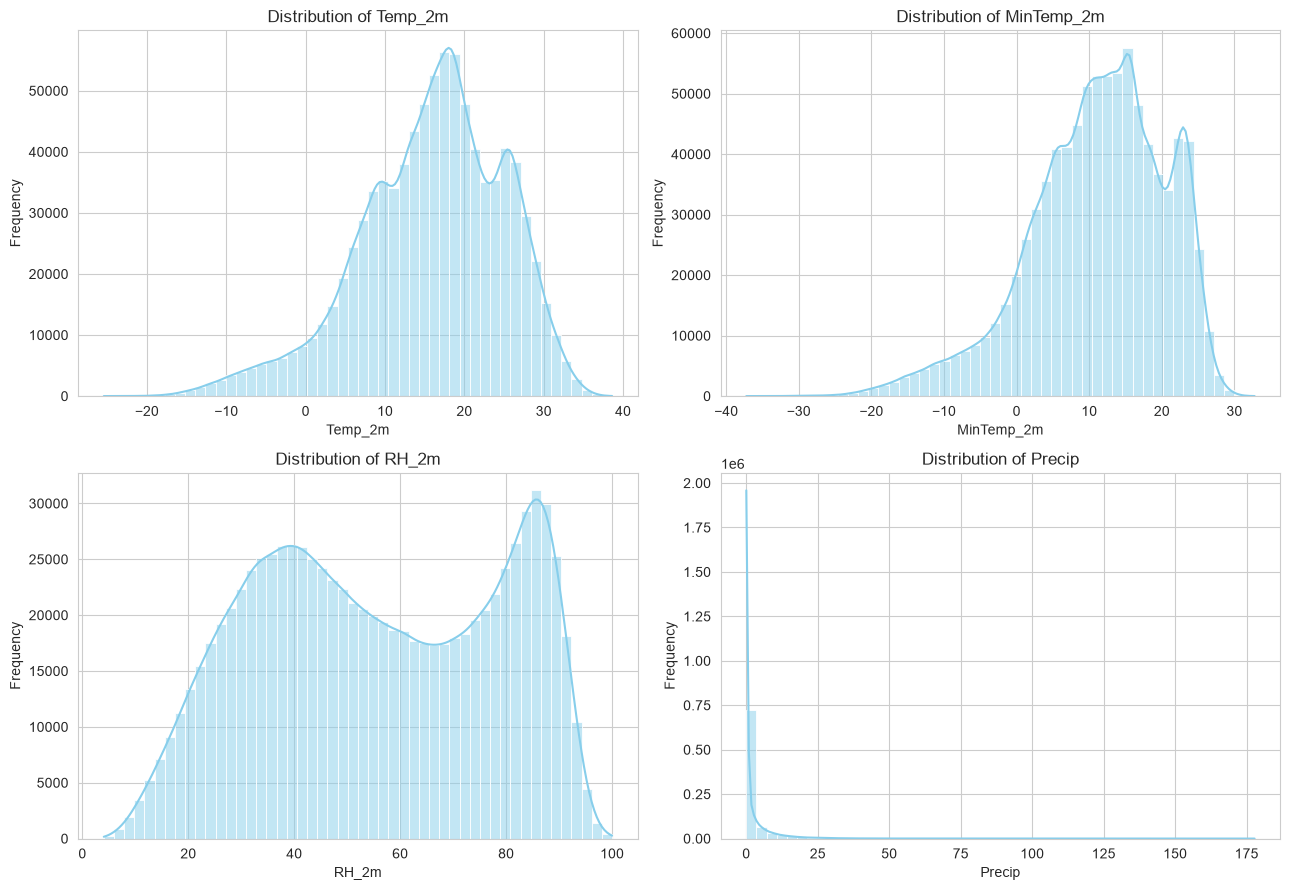

In [11]:
#distribution of selected variables
num_features = ["Temp_2m", "MinTemp_2m", "RH_2m", "Precip"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.histplot(df[col], kde=True, bins=50, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("outputs/eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

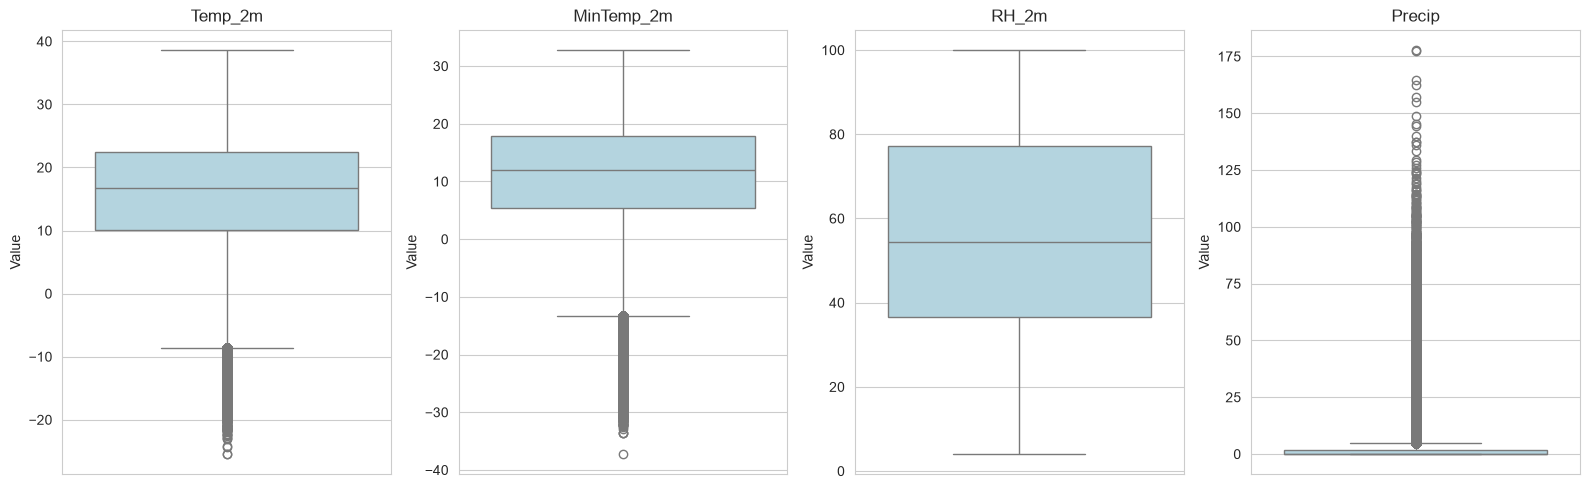

In [12]:
#outlier detection
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, col in enumerate(num_features):
    sns.boxplot(y=df[col], ax=axes[i], color="lightblue")
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")

plt.tight_layout()
plt.show()

Precip is very skewed, most days are almost 0 and some monsoon days have very heavy rain. I didn't
remove these because they are real values, not mistakes. Tree models can handle this anyway.

# **Decoding date and season**

In [13]:
df["Date"] = pd.to_datetime(df["Date"])

# sort by district and date (needed later for lag features)
df = df.sort_values(by=["District", "Date"]).reset_index(drop=True)

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfYear"] = df["Date"].dt.dayofyear

def nepal_season_from_month(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Pre-Monsoon"
    elif m in [6, 7, 8, 9]:
        return "Monsoon"
    else:  # 10, 11
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(nepal_season_from_month)

season_mapping = {"Winter": 0, "Pre-Monsoon": 1, "Monsoon": 2, "Post-Monsoon": 3}
df["Season_encoded"] = df["Season"].map(season_mapping)

# sin and cos of day of year, so 31 dec and 1 jan comes close
df["doy_sin"] = np.sin(2 * np.pi * df["DayOfYear"] / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * df["DayOfYear"] / 365.25)

In [14]:
print(df[["Date", "Year", "Month", "DayOfYear", "Season", "Season_encoded"]].head(10))

print("\nNumber of records per season:")
print(df["Season"].value_counts())

        Date  Year  Month  DayOfYear  Season  Season_encoded
0 1981-01-01  1981      1          1  Winter               0
1 1981-01-02  1981      1          2  Winter               0
2 1981-01-03  1981      1          3  Winter               0
3 1981-01-04  1981      1          4  Winter               0
4 1981-01-05  1981      1          5  Winter               0
5 1981-01-06  1981      1          6  Winter               0
6 1981-01-07  1981      1          7  Winter               0
7 1981-01-08  1981      1          8  Winter               0
8 1981-01-09  1981      1          9  Winter               0
9 1981-01-10  1981      1         10  Winter               0

Number of records per season:
Season
Monsoon         294996
Pre-Monsoon     222456
Winter          218178
Post-Monsoon    147498
Name: count, dtype: int64


# **EDA (Seasonal Trends)**

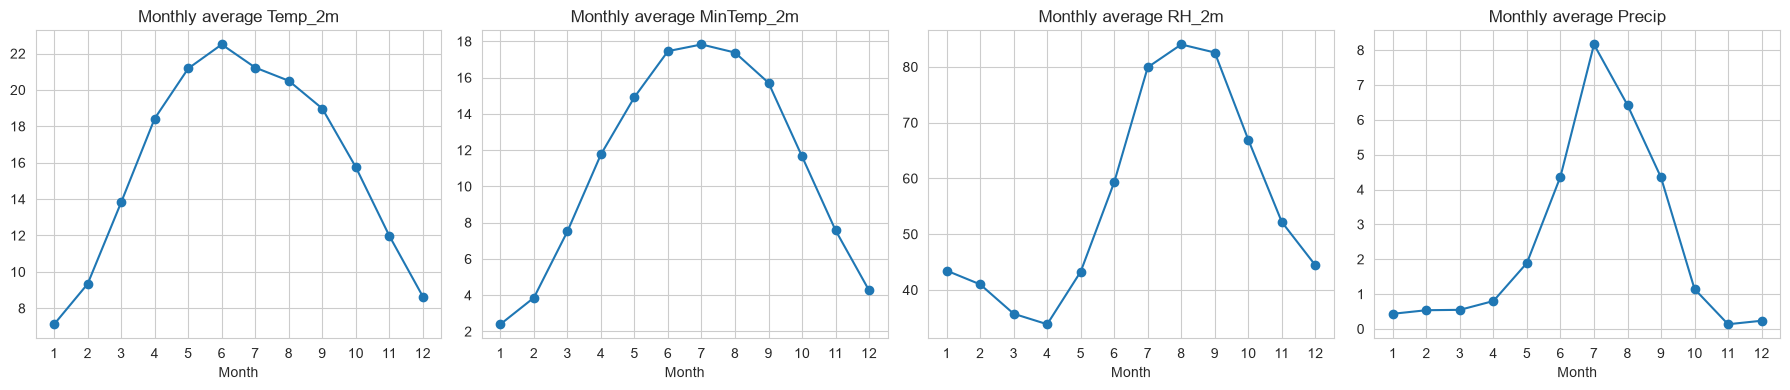

In [15]:
#monthly average of each variable (separate plots because units are different)
monthly_avg = df.groupby("Month")[num_features].mean().reset_index()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(num_features):
    axes[i].plot(monthly_avg["Month"], monthly_avg[col], marker="o")
    axes[i].set_title(f"Monthly average {col}")
    axes[i].set_xlabel("Month")
    axes[i].set_xticks(range(1, 13))

plt.tight_layout()
plt.savefig("outputs/eda_monthly.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
#seasonal averages overall Nepal
seasonal_avg = df.groupby("Season")[num_features].mean()
seasonal_avg = seasonal_avg.reindex(["Winter", "Pre-Monsoon", "Monsoon", "Post-Monsoon"])
print(seasonal_avg.round(2))

              Temp_2m  MinTemp_2m  RH_2m  Precip
Season                                          
Winter           8.34        3.50  43.03    0.40
Pre-Monsoon     17.80       11.40  37.66    1.08
Monsoon         20.80       17.11  76.56    5.85
Post-Monsoon    13.90        9.65  59.69    0.65


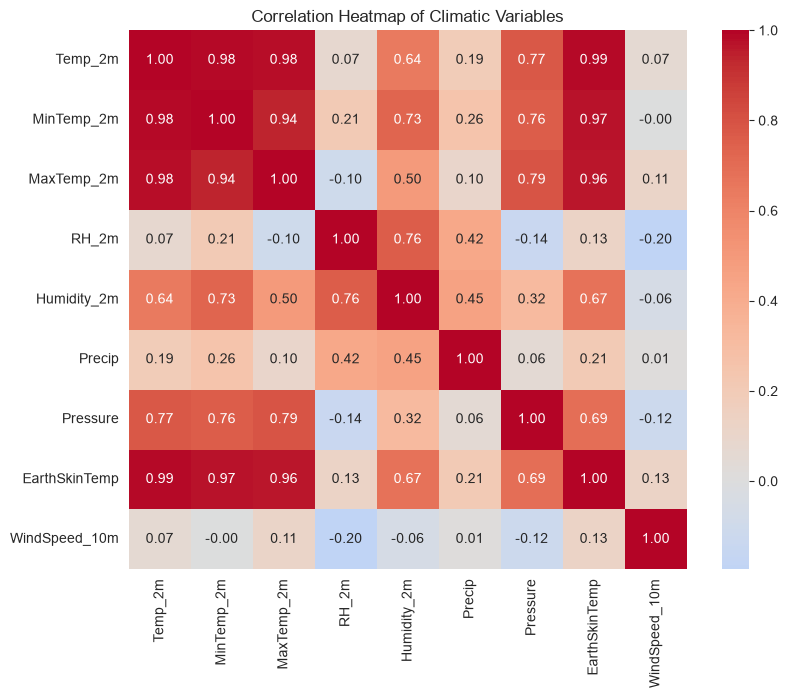

In [17]:
corr_vars = ["Temp_2m", "MinTemp_2m", "MaxTemp_2m", "RH_2m", "Humidity_2m", "Precip",
             "Pressure", "EarthSkinTemp", "WindSpeed_10m"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_vars].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap of Climatic Variables")
plt.savefig("outputs/eda_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

# **Generate TLB Label (Target Variable)**

I don't have any field data of blight cases, so I am using the weather rule that is commonly used
for late blight. A day is TLB favourable when:

- RH is more than 80%
- minimum temperature is less than 10 °C

So this label means "good weather for the disease", it doesn't mean the disease actually happened.

In [18]:
df["TLB_today"] = ((df["RH_2m"] > 80) & (df["MinTemp_2m"] < 10)).astype(int)

# check distribution
print(df["TLB_today"].value_counts())
print("Positive %:", round(df["TLB_today"].mean() * 100, 2))

TLB_today
0    853833
1     29295
Name: count, dtype: int64
Positive %: 3.32


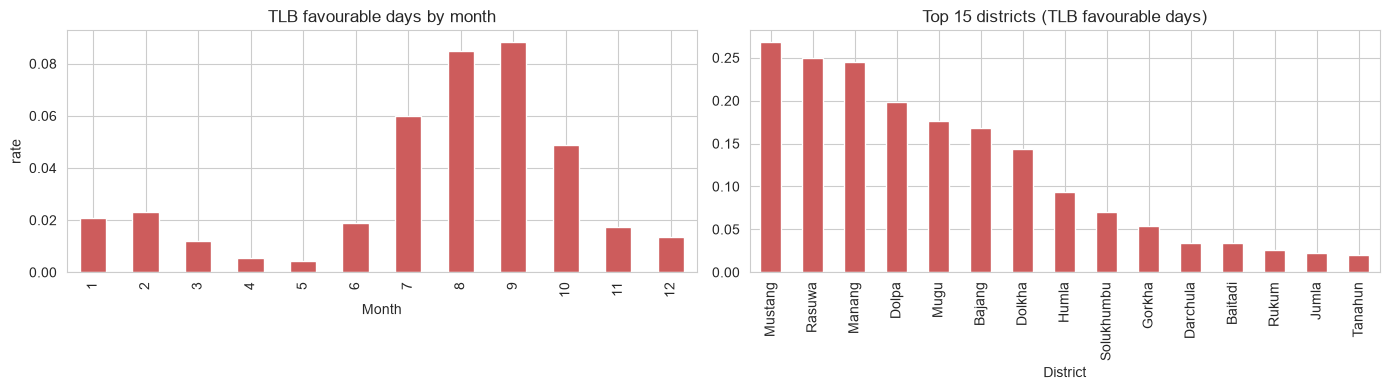

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# by month
month_rate = df.groupby("Month")["TLB_today"].mean()
month_rate.plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("TLB favourable days by month")
axes[0].set_ylabel("rate")

# top 15 districts
district_rate = df.groupby("District")["TLB_today"].mean().sort_values(ascending=False)
district_rate.head(15).plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Top 15 districts (TLB favourable days)")

plt.tight_layout()
plt.savefig("outputs/label_month_district.png", dpi=150, bbox_inches="tight")
plt.show()

Only about 3% of the days are positive, so the data is very imbalanced. Most of them are in the
monsoon (Jul-Sep) in the high mountain districts, where it is humid and the nights are still cold.

For the target I am using the label of the **next day**, because the idea is to warn farmers one day
before. So the model only gets today's and past days' weather.

In [20]:
# target = tomorrow's label for the same district
df["TLB_next"] = df.groupby("District")["TLB_today"].shift(-1)

print(df[["Date", "District", "TLB_today", "TLB_next"]].head(10))

        Date      District  TLB_today  TLB_next
0 1981-01-01  Arghakhanchi          0       0.0
1 1981-01-02  Arghakhanchi          0       0.0
2 1981-01-03  Arghakhanchi          0       0.0
3 1981-01-04  Arghakhanchi          0       0.0
4 1981-01-05  Arghakhanchi          0       0.0
5 1981-01-06  Arghakhanchi          0       0.0
6 1981-01-07  Arghakhanchi          0       0.0
7 1981-01-08  Arghakhanchi          0       0.0
8 1981-01-09  Arghakhanchi          0       0.0
9 1981-01-10  Arghakhanchi          0       0.0


# **Feature Engineering**

In [21]:
# yesterday and day before
df["RH_2m_lag1"] = df.groupby("District")["RH_2m"].shift(1)
df["RH_2m_lag2"] = df.groupby("District")["RH_2m"].shift(2)
df["MinTemp_2m_lag1"] = df.groupby("District")["MinTemp_2m"].shift(1)
df["MinTemp_2m_lag2"] = df.groupby("District")["MinTemp_2m"].shift(2)
df["Temp_2m_lag1"] = df.groupby("District")["Temp_2m"].shift(1)
df["Temp_2m_lag2"] = df.groupby("District")["Temp_2m"].shift(2)
df["Precip_lag1"] = df.groupby("District")["Precip"].shift(1)
df["Precip_lag2"] = df.groupby("District")["Precip"].shift(2)

In [22]:
# rolling mean of last 3 and 7 days (today included)
for col in ["RH_2m", "MinTemp_2m", "Precip", "Temp_2m"]:
    df[col + "_mean3"] = df.groupby("District")[col].transform(lambda x: x.rolling(3).mean())
    df[col + "_mean7"] = df.groupby("District")[col].transform(lambda x: x.rolling(7).mean())

# total rain in last 7 days
df["Precip_sum7"] = df.groupby("District")["Precip"].transform(lambda x: x.rolling(7).sum())

In [23]:
# humid streak: RH > 80 for 3 days in a row
df["humid_day"] = (df["RH_2m"] > 80).astype(int)

df["humid_streak3"] = (
    df.groupby("District")["humid_day"]
    .transform(lambda x: x.rolling(3).sum() == 3)
).astype(int)

# how many humid days in last week
df["humid_days7"] = df.groupby("District")["humid_day"].transform(lambda x: x.rolling(7).sum())

# how many TLB favourable days in last week
df["tlb_days7"] = df.groupby("District")["TLB_today"].transform(lambda x: x.rolling(7).sum())

# change from yesterday
df["RH_change"] = df["RH_2m"] - df["RH_2m_lag1"]
df["MinTemp_change"] = df["MinTemp_2m"] - df["MinTemp_2m_lag1"]

print(df[["Date", "District", "RH_2m", "humid_streak3", "humid_days7", "tlb_days7"]].head(10))

        Date      District  RH_2m  humid_streak3  humid_days7  tlb_days7
0 1981-01-01  Arghakhanchi  45.41              0          NaN        NaN
1 1981-01-02  Arghakhanchi  46.78              0          NaN        NaN
2 1981-01-03  Arghakhanchi  47.91              0          NaN        NaN
3 1981-01-04  Arghakhanchi  50.83              0          NaN        NaN
4 1981-01-05  Arghakhanchi  55.55              0          NaN        NaN
5 1981-01-06  Arghakhanchi  59.18              0          NaN        NaN
6 1981-01-07  Arghakhanchi  65.22              0          0.0        0.0
7 1981-01-08  Arghakhanchi  57.60              0          0.0        0.0
8 1981-01-09  Arghakhanchi  53.49              0          0.0        0.0
9 1981-01-10  Arghakhanchi  51.00              0          0.0        0.0


In [24]:
# first days of each district dont have lag values and last day has no TLB_next
print("Rows before:", len(df))
df = df.dropna().reset_index(drop=True)
df["TLB_next"] = df["TLB_next"].astype(int)
print("Rows after:", len(df))

Rows before: 883128


Rows after: 882694


In [25]:
# features for the model
features = [
    # weather of today
    "Precip", "Pressure", "RH_2m", "Humidity_2m", "Temp_2m", "WetBulbTemp_2m",
    "MaxTemp_2m", "MinTemp_2m", "TempRange_2m", "EarthSkinTemp", "WindSpeed_10m", "WindSpeed_50m",
    # lags
    "RH_2m_lag1", "RH_2m_lag2", "MinTemp_2m_lag1", "MinTemp_2m_lag2",
    "Temp_2m_lag1", "Temp_2m_lag2", "Precip_lag1", "Precip_lag2",
    # rolling
    "RH_2m_mean3", "RH_2m_mean7", "MinTemp_2m_mean3", "MinTemp_2m_mean7",
    "Precip_mean3", "Precip_mean7", "Temp_2m_mean3", "Temp_2m_mean7",
    "Precip_sum7", "humid_streak3", "humid_days7", "tlb_days7", "RH_change", "MinTemp_change",
    # location and time (lat/lon instead of one-hot of 62 districts)
    "Latitude", "Longitude", "Month", "Season_encoded", "doy_sin", "doy_cos",
    # today's label
    "TLB_today",
]
print("No. of features:", len(features))

No. of features: 41


# **Train / Validation / Test split by year**

Weather of nearby days is almost the same, so if I split randomly, the model sees almost the same days
in train and test and the score looks better than it really is. So I split by year:

- train: 1981-2011
- validation: 2012-2015 (for tuning and choosing the threshold)
- test: 2016-2019 (only used at the end)

In [26]:
train = df[df["Year"] <= 2011]
val = df[(df["Year"] >= 2012) & (df["Year"] <= 2015)]
test = df[df["Year"] >= 2016]

X_train = train[features].astype("float32")
y_train = train["TLB_next"]

X_val = val[features].astype("float32")
y_val = val["TLB_next"]

X_test = test[features].astype("float32")
y_test = test["TLB_next"]

print("Train:", X_train.shape, " positive %:", round(y_train.mean() * 100, 2))
print("Val:  ", X_val.shape, " positive %:", round(y_val.mean() * 100, 2))
print("Test: ", X_test.shape, " positive %:", round(y_test.mean() * 100, 2))

Train: (701592, 41)  positive %: 2.82
Val:   (90582, 41)  positive %: 5.62
Test:  (90520, 41)  positive %: 4.87


I am using class weights for the imbalance instead of SMOTE. SMOTE makes fake days by mixing nearby
rows which doesn't really make sense for time series data, and in my old notebook I did it before the
split which was wrong.

Accuracy is not useful here because if the model just says 0 every time it still gets ~97%. So I am
looking at F1, recall and PR-AUC mostly. I choose the threshold on the validation set (where F1 is
highest) and use the same threshold for the test set.

In [27]:
# ratio of negative to positive, used as weight in xgboost
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("neg/pos:", round(pos_weight, 1))


# find threshold with best F1 on validation set
def find_threshold(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    best = np.argmax(f1[:-1])
    return thresholds[best]


def get_scores(name, y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)
    scores = {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
        "PR_AUC": average_precision_score(y_true, y_proba),
    }
    return scores


# all test results will be saved here
results = []
test_probs = {}

neg/pos: 34.5


# **Baseline Models**

First a very simple baseline: just say tomorrow will be the same as today. Weather doesn't change
much day to day, so this is actually hard to beat. If my models can't beat this, they are not useful.

In [28]:
# baseline: tomorrow = today
y_proba_base = test["TLB_today"].values.astype(float)

base_scores = get_scores("Baseline (today = tomorrow)", y_test, y_proba_base, 0.5)
results.append(base_scores)
test_probs["Baseline (today = tomorrow)"] = y_proba_base

print(base_scores)

{'Model': 'Baseline (today = tomorrow)', 'Threshold': 0.5, 'Accuracy': 0.9724149359257622, 'Precision': 0.7170068027210884, 'Recall': 0.716844253003854, 'F1': 0.7169255186486793, 'ROC_AUC': 0.8511754972297255, 'PR_AUC': 0.5277802615735835}


In [29]:
# logistic regression (needs scaling, so scaler inside pipeline)
logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
logreg.fit(X_train, y_train)

y_val_lr = logreg.predict_proba(X_val)[:, 1]
y_test_lr = logreg.predict_proba(X_test)[:, 1]

thr_lr = find_threshold(y_val, y_val_lr)
lr_scores = get_scores("Logistic Regression", y_test, y_test_lr, thr_lr)
results.append(lr_scores)
test_probs["Logistic Regression"] = y_test_lr

print(lr_scores)

{'Model': 'Logistic Regression', 'Threshold': np.float32(0.96555316), 'Accuracy': 0.971177640300486, 'Precision': 0.6946004319654427, 'Recall': 0.7290863749716617, 'F1': 0.7114257272425617, 'ROC_AUC': 0.9798258758461117, 'PR_AUC': 0.7396568058390275}


In [30]:
# decision tree
dtree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced", random_state=42)
dtree.fit(X_train, y_train)

y_val_dt = dtree.predict_proba(X_val)[:, 1]
y_test_dt = dtree.predict_proba(X_test)[:, 1]

thr_dt = find_threshold(y_val, y_val_dt)
dt_scores = get_scores("Decision Tree", y_test, y_test_dt, thr_dt)
results.append(dt_scores)
test_probs["Decision Tree"] = y_test_dt

print(dt_scores)

{'Model': 'Decision Tree', 'Threshold': np.float64(0.9557444958856738), 'Accuracy': 0.9731551038444543, 'Precision': 0.7116905321649926, 'Recall': 0.7549308546814781, 'F1': 0.7326732673267327, 'ROC_AUC': 0.9673184658568549, 'PR_AUC': 0.7828683273999809}


# **Random Forest**

In [31]:
%%time
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_features="sqrt",
    max_samples=0.5,      # half rows for each tree, otherwise very slow
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train)

y_val_rf = rf.predict_proba(X_val)[:, 1]
y_test_rf = rf.predict_proba(X_test)[:, 1]

thr_rf = find_threshold(y_val, y_val_rf)
rf_scores = get_scores("Random Forest", y_test, y_test_rf, thr_rf)
results.append(rf_scores)
test_probs["Random Forest"] = y_test_rf

print(rf_scores)

{'Model': 'Random Forest', 'Threshold': np.float64(0.5974686127102025), 'Accuracy': 0.9724259832081308, 'Precision': 0.6898671425738647, 'Recall': 0.7887100430741328, 'F1': 0.7359847683520203, 'ROC_AUC': 0.9872633184052924, 'PR_AUC': 0.8359590695966748}
CPU times: user 7min 52s, sys: 9.46 s, total: 8min 1s
Wall time: 1min 24s


# **XGBoost**

In [32]:
%%time
xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    tree_method="hist",
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=42
)
xgb.fit(X_train, y_train)

y_val_xgb = xgb.predict_proba(X_val)[:, 1]
y_test_xgb = xgb.predict_proba(X_test)[:, 1]

thr_xgb = find_threshold(y_val, y_val_xgb)
xgb_scores = get_scores("XGBoost", y_test, y_test_xgb, thr_xgb)
results.append(xgb_scores)
test_probs["XGBoost"] = y_test_xgb

print(xgb_scores)

{'Model': 'XGBoost', 'Threshold': np.float32(0.88181597), 'Accuracy': 0.9745581087052585, 'Precision': 0.7329796640141468, 'Recall': 0.7517569712083427, 'F1': 0.7422495803021825, 'ROC_AUC': 0.9868133356751375, 'PR_AUC': 0.8349738635906448}
CPU times: user 2min 19s, sys: 15.4 s, total: 2min 34s
Wall time: 27.1 s


# **CatBoost**

In [33]:
%%time
cat = CatBoostClassifier(
    iterations=600,
    learning_rate=0.1,
    depth=6,
    auto_class_weights="Balanced",
    eval_metric="PRAUC",
    random_seed=42,
    thread_count=-1,
    verbose=0
)

# validation set for early stopping
cat.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)
print("Best iteration:", cat.get_best_iteration())

y_val_cat = cat.predict_proba(X_val)[:, 1]
y_test_cat = cat.predict_proba(X_test)[:, 1]

thr_cat = find_threshold(y_val, y_val_cat)
cat_scores = get_scores("CatBoost", y_test, y_test_cat, thr_cat)
results.append(cat_scores)
test_probs["CatBoost"] = y_test_cat

print(cat_scores)

Best iteration: 126
{'Model': 'CatBoost', 'Threshold': np.float64(0.9106243269161034), 'Accuracy': 0.971730004418913, 'Precision': 0.6743879472693032, 'Recall': 0.8118340512355475, 'F1': 0.7367554778314989, 'ROC_AUC': 0.9879154761799733, 'PR_AUC': 0.8364872881281739}
CPU times: user 1min 43s, sys: 7.37 s, total: 1min 50s
Wall time: 33.7 s


# **XGBoost Hypertuning**

I tried a few different settings. Each one is trained on train years and checked on validation years
using PR-AUC. Early stopping decides how many trees to use. I am not touching the test set here.

In [34]:
%%time
# settings i want to try
param_list = [
    {"max_depth": 4,  "learning_rate": 0.05, "min_child_weight": 1,  "subsample": 0.8, "colsample_bytree": 0.8},
    {"max_depth": 6,  "learning_rate": 0.05, "min_child_weight": 5,  "subsample": 0.8, "colsample_bytree": 0.8},
    {"max_depth": 8,  "learning_rate": 0.05, "min_child_weight": 5,  "subsample": 0.8, "colsample_bytree": 0.6},
    {"max_depth": 6,  "learning_rate": 0.03, "min_child_weight": 10, "subsample": 0.7, "colsample_bytree": 0.7},
    {"max_depth": 10, "learning_rate": 0.05, "min_child_weight": 20, "subsample": 0.8, "colsample_bytree": 0.6},
]

tuning_results = []
best_score = 0
xgb_tuned = None

for p in param_list:
    model = XGBClassifier(
        n_estimators=2000,
        max_depth=p["max_depth"],
        learning_rate=p["learning_rate"],
        min_child_weight=p["min_child_weight"],
        subsample=p["subsample"],
        colsample_bytree=p["colsample_bytree"],
        scale_pos_weight=pos_weight,
        tree_method="hist",
        eval_metric="aucpr",
        early_stopping_rounds=50,
        n_jobs=-1,
        random_state=42
    )
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    val_proba = model.predict_proba(X_val)[:, 1]
    val_pr_auc = average_precision_score(y_val, val_proba)
    print(p, "trees:", model.best_iteration + 1, "val PR_AUC:", round(val_pr_auc, 4))

    row = p.copy()
    row["trees"] = model.best_iteration + 1
    row["val_PR_AUC"] = val_pr_auc
    tuning_results.append(row)

    # keep the best one
    if val_pr_auc > best_score:
        best_score = val_pr_auc
        xgb_tuned = model

tuning_df = pd.DataFrame(tuning_results).sort_values("val_PR_AUC", ascending=False)
tuning_df.to_csv("outputs/xgb_tuning.csv", index=False)
tuning_df

{'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 1, 'subsample': 0.8, 'colsample_bytree': 0.8} trees: 254 val PR_AUC: 0.8203


{'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8} trees: 175 val PR_AUC: 0.8239


{'max_depth': 8, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.6} trees: 91 val PR_AUC: 0.8236


{'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 10, 'subsample': 0.7, 'colsample_bytree': 0.7} trees: 255 val PR_AUC: 0.8254


{'max_depth': 10, 'learning_rate': 0.05, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.6} trees: 100 val PR_AUC: 0.8259
CPU times: user 10min 30s, sys: 52.7 s, total: 11min 23s
Wall time: 1min 54s


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,trees,val_PR_AUC
4,10,0.05,20,0.8,0.6,100,0.825923
3,6,0.03,10,0.7,0.7,255,0.825398
1,6,0.05,5,0.8,0.8,175,0.823906
2,8,0.05,5,0.8,0.6,91,0.823568
0,4,0.05,1,0.8,0.8,254,0.820286


In [35]:
# evaluate best tuned model on test set
y_val_tuned = xgb_tuned.predict_proba(X_val)[:, 1]
y_test_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

thr_tuned = find_threshold(y_val, y_val_tuned)
tuned_scores = get_scores("XGBoost (tuned)", y_test, y_test_tuned, thr_tuned)
results.append(tuned_scores)
test_probs["XGBoost (tuned)"] = y_test_tuned

print(tuned_scores)

{'Model': 'XGBoost (tuned)', 'Threshold': np.float32(0.87761396), 'Accuracy': 0.973541758727353, 'Precision': 0.7032258064516129, 'Recall': 0.7907503967354341, 'F1': 0.7444242876960837, 'ROC_AUC': 0.9877727966740967, 'PR_AUC': 0.8408793359820959}


# **Comparing all models (test set 2016-2019)**

In [36]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df = results_df.sort_values("PR_AUC", ascending=False)
results_df.to_csv("outputs/model_comparison.csv")
results_df

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,,
XGBoost (tuned),0.8776,0.9735,0.7032,0.7908,0.7444,0.9878,0.8409
CatBoost,0.9106,0.9717,0.6744,0.8118,0.7368,0.9879,0.8365
Random Forest,0.5975,0.9724,0.6899,0.7887,0.7360,0.9873,0.8360
XGBoost,0.8818,0.9746,0.7330,0.7518,0.7422,0.9868,0.8350
Decision Tree,0.9557,0.9732,0.7117,0.7549,0.7327,0.9673,0.7829
Logistic Regression,0.9656,0.9712,0.6946,0.7291,0.7114,0.9798,0.7397
Baseline (today = tomorrow),0.5000,0.9724,0.7170,0.7168,0.7169,0.8512,0.5278


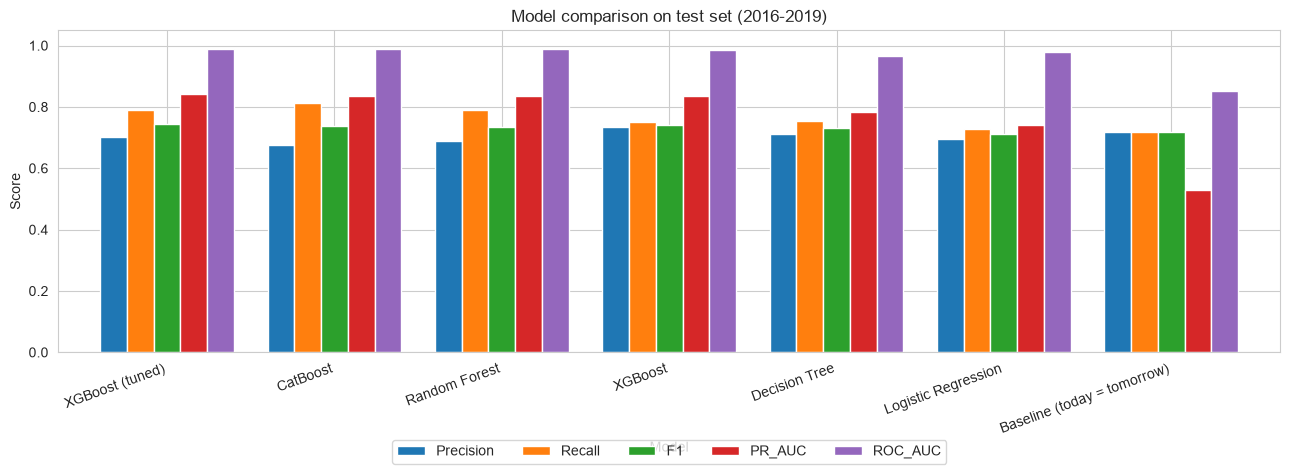

In [37]:
results_df[["Precision", "Recall", "F1", "PR_AUC", "ROC_AUC"]].plot(kind="bar", figsize=(13, 5), width=0.8)
plt.title("Model comparison on test set (2016-2019)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

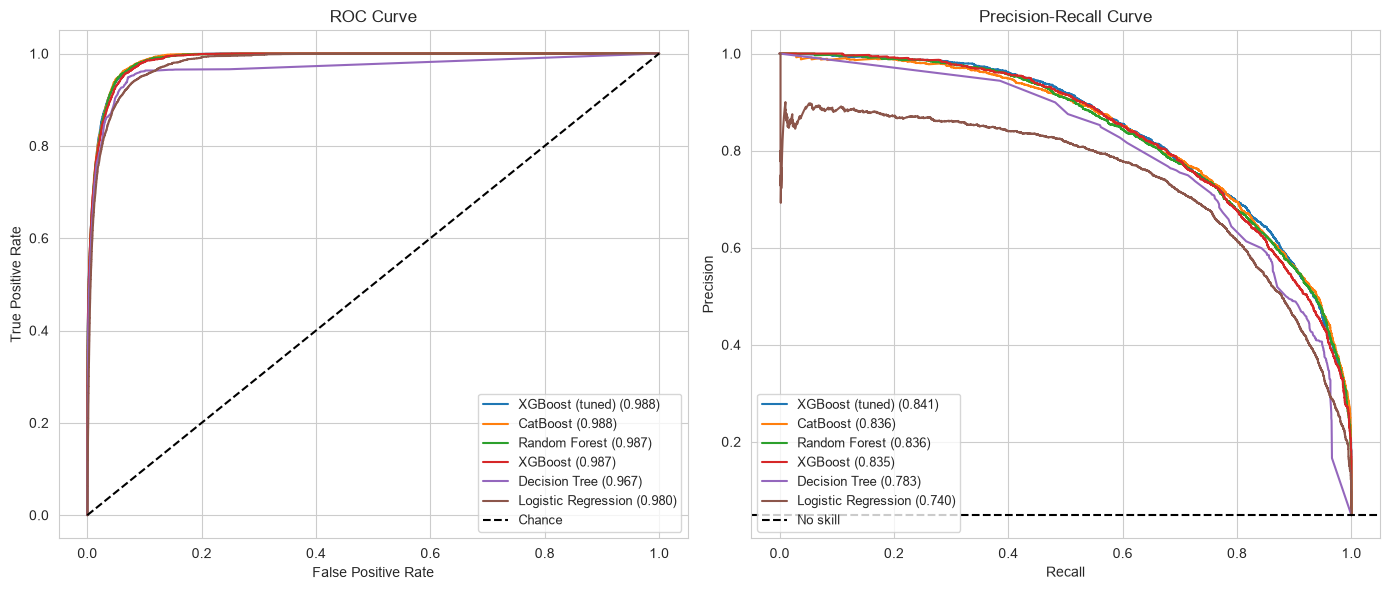

In [38]:
# ROC and PR curves (baseline not included, it only gives 0 or 1)
model_names = ["XGBoost (tuned)", "CatBoost", "Random Forest", "XGBoost", "Decision Tree", "Logistic Regression"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name in model_names:
    proba = test_probs[name]

    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_score = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} ({auc_score:.3f})")

    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(recall, precision, label=f"{name} ({ap:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="black", label="Chance")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(y_test.mean(), linestyle="--", color="black", label="No skill")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.savefig("outputs/roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Threshold: 0.878

Classification Report:
              precision    recall  f1-score   support

           0     0.9892    0.9829    0.9860     86109
           1     0.7032    0.7908    0.7444      4411

    accuracy                         0.9735     90520
   macro avg     0.8462    0.8868    0.8652     90520
weighted avg     0.9753    0.9735    0.9743     90520



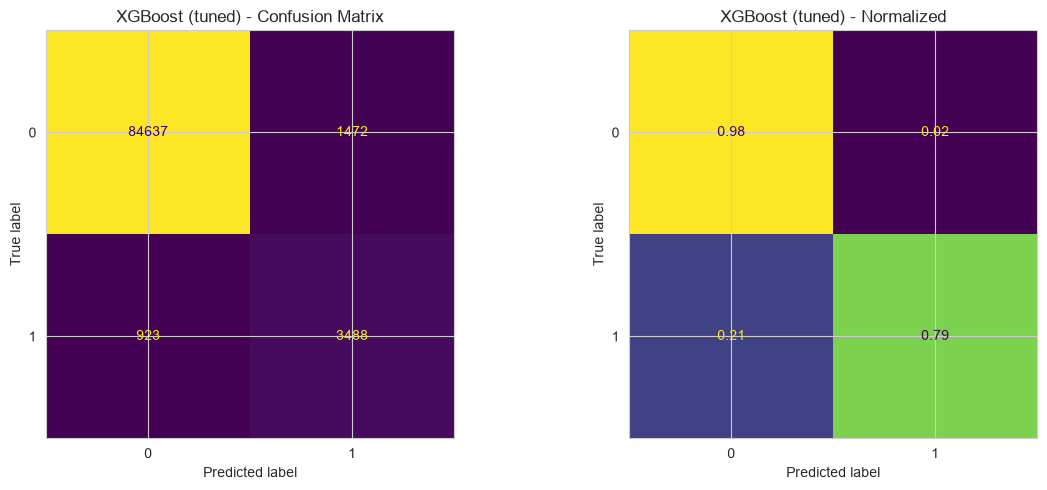

In [39]:
# tuned xgboost is the best (highest PR-AUC and F1), so looking at it in detail
y_pred_best = (y_test_tuned >= thr_tuned).astype(int)

print("Threshold:", round(thr_tuned, 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, digits=4))

cm = confusion_matrix(y_test, y_pred_best)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("XGBoost (tuned) - Confusion Matrix")
ConfusionMatrixDisplay(cm_norm).plot(ax=axes[1], values_format=".2f", colorbar=False)
axes[1].set_title("XGBoost (tuned) - Normalized")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix_best.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
# checking each test year separately
year_results = []
for year in [2016, 2017, 2018, 2019]:
    mask = (test["Year"] == year).values
    s = get_scores(year, y_test[mask], y_test_tuned[mask], thr_tuned)
    year_results.append(s)

year_df = pd.DataFrame(year_results).rename(columns={"Model": "Year"}).set_index("Year")
year_df.drop(columns="Threshold").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Year,,,,,,
2016,0.9804,0.7217,0.8522,0.7815,0.9925,0.8832
2017,0.9754,0.6941,0.8238,0.7534,0.9885,0.8544
2018,0.9807,0.7306,0.8493,0.7855,0.9927,0.8800
2019,0.9576,0.6777,0.6931,0.6853,0.9769,0.7734


# **Feature Importance and SHAP**

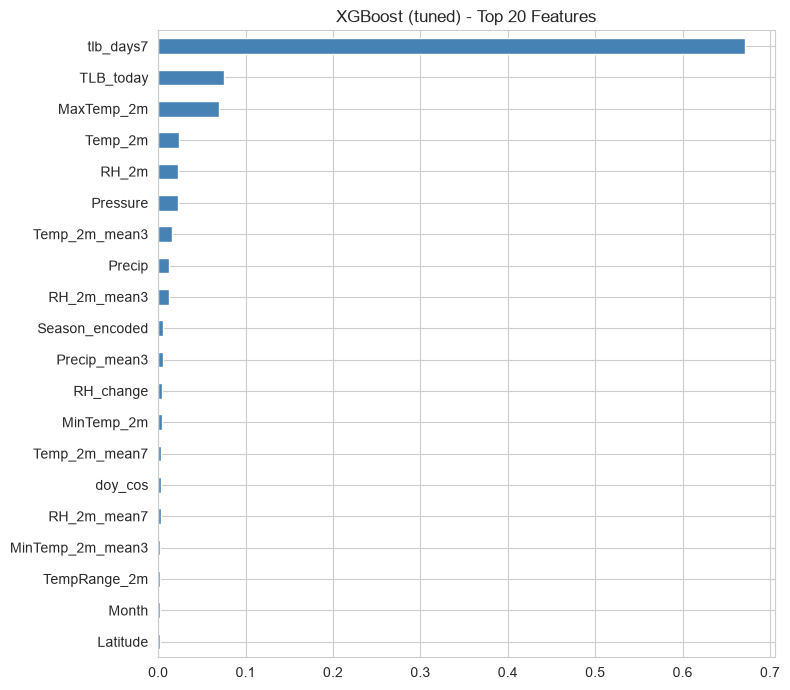

In [41]:
importance = pd.Series(xgb_tuned.feature_importances_, index=features)
importance = importance.sort_values(ascending=False)

plt.figure(figsize=(8, 7))
importance.head(20).sort_values().plot(kind="barh", color="steelblue")
plt.title("XGBoost (tuned) - Top 20 Features")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

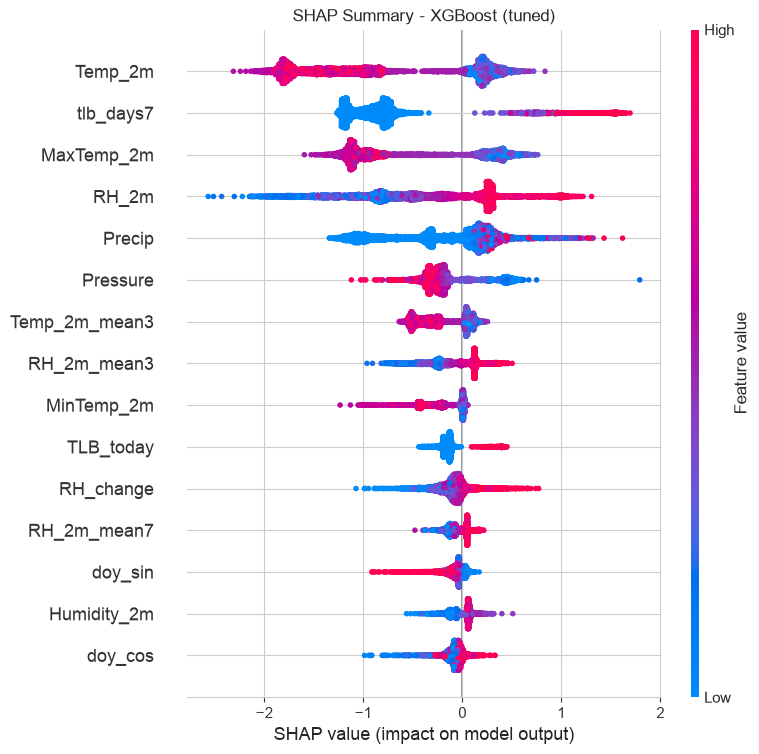

In [42]:
# SHAP only on 5000 rows, full test set takes too long
sample = X_test.sample(5000, random_state=42)

explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, max_display=15, show=False)
plt.title("SHAP Summary - XGBoost (tuned)")
plt.savefig("outputs/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

What I see from the SHAP plot:
- temperature (Temp_2m, MaxTemp_2m) is the most important. When it is cold the risk goes up, this
  is how the model finds the mountain districts
- tlb_days7 is second, so if there were many favourable days in the last week, tomorrow is also likely
- high RH and rain increase the risk, which is what I expected
- pressure is low in high places, so it works like altitude

# **Risk by District and Season (2016-2019)**

In [43]:
risk_df = test[["District", "Latitude", "Longitude", "Season", "Year", "TLB_next"]].copy()
risk_df["Predicted_Risk"] = y_test_tuned

# mean risk of each district
dist_risk = risk_df.groupby(["District", "Latitude", "Longitude"], as_index=False).agg(
    Mean_Risk=("Predicted_Risk", "mean"),
    Observed_Rate=("TLB_next", "mean")
)
dist_risk = dist_risk.sort_values("Mean_Risk", ascending=False)
dist_risk.to_csv("outputs/district_risk.csv", index=False)

print("Top 10 districts by predicted risk:")
print(dist_risk.head(10).round(4))

Top 10 districts by predicted risk:
      District  Latitude  Longitude  Mean_Risk  Observed_Rate
34      Manang      28.6       84.2     0.5986         0.4260
37     Mustang      28.9       83.8     0.5706         0.3904
45      Rasuwa      28.1       85.3     0.5206         0.3178
17       Dolpa      29.0       82.9     0.5016         0.3034
36        Mugu      29.5       82.1     0.4891         0.2842
3       Bajang      29.6       81.2     0.4422         0.2336
21       Humla      30.0       81.8     0.4210         0.1568
16      Dolkha      27.6       86.2     0.3917         0.1541
54  Solukhumbu      28.0       86.8     0.2960         0.1479
19      Gorkha      28.0       84.6     0.2092         0.0863


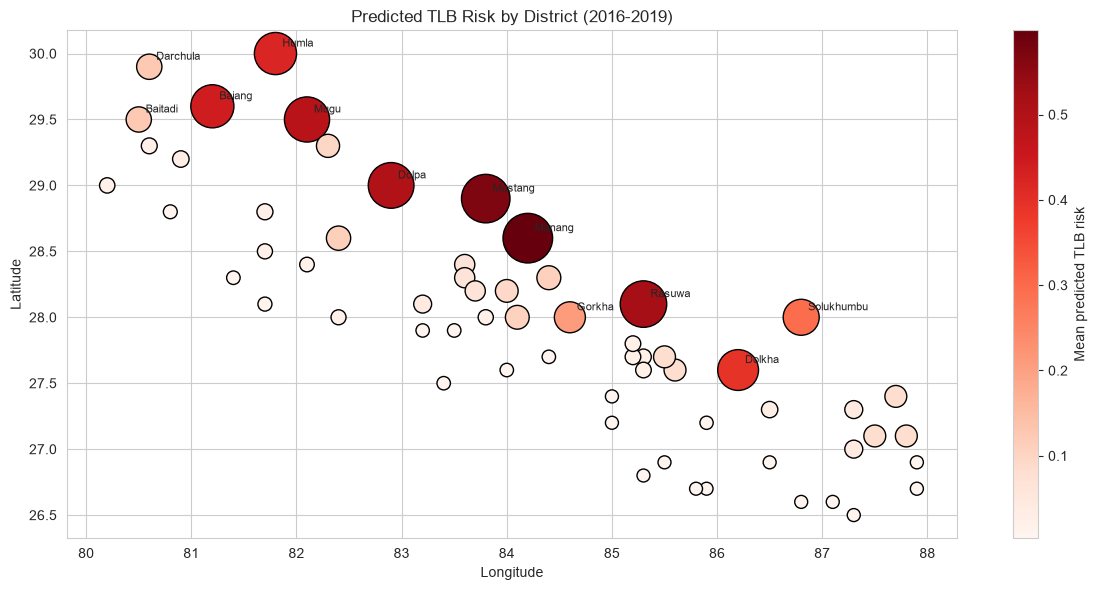

In [44]:
# map of districts using lat/lon (no geojson needed), bigger and darker = more risk
plt.figure(figsize=(12, 6))
sc = plt.scatter(dist_risk["Longitude"], dist_risk["Latitude"],
                 c=dist_risk["Mean_Risk"], s=80 + 2000 * dist_risk["Mean_Risk"],
                 cmap="Reds", edgecolor="black")

# names of top 12 districts
for i, row in dist_risk.head(12).iterrows():
    plt.annotate(row["District"], (row["Longitude"], row["Latitude"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.colorbar(sc, label="Mean predicted TLB risk")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Predicted TLB Risk by District (2016-2019)")
plt.tight_layout()
plt.savefig("outputs/risk_map.png", dpi=150, bbox_inches="tight")
plt.show()

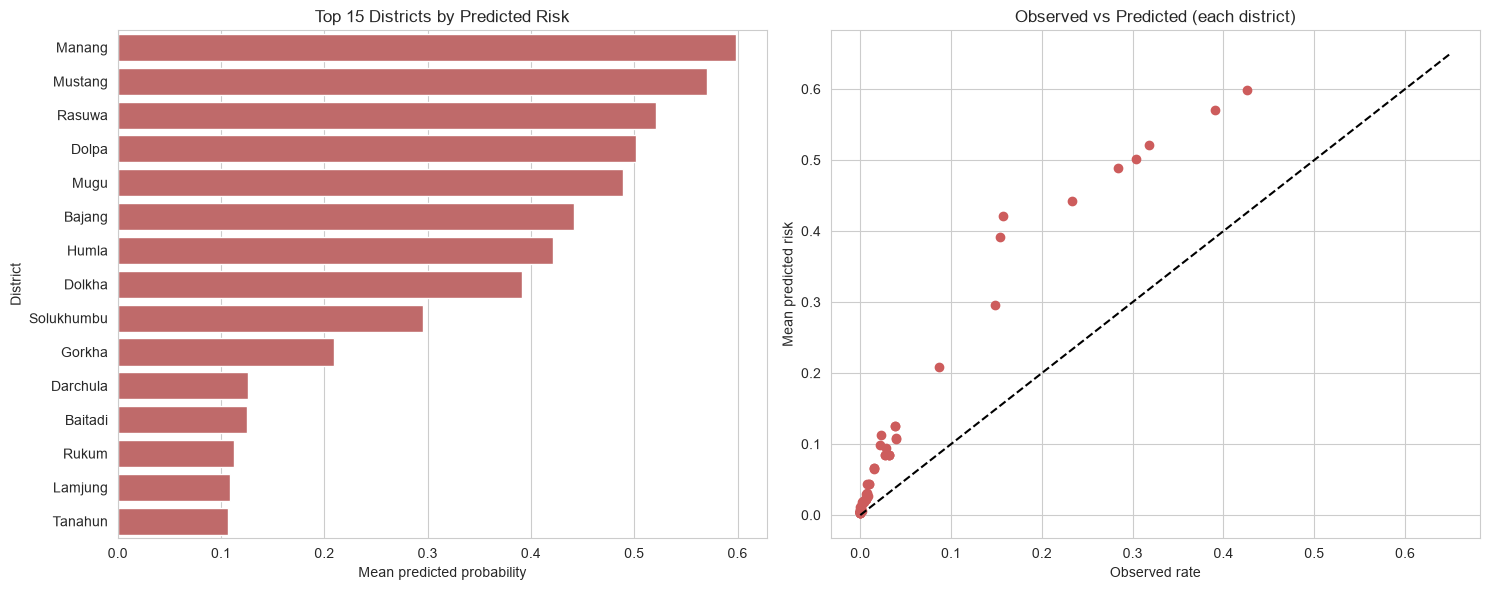

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# top 15 districts
top15 = dist_risk.head(15)
sns.barplot(data=top15, y="District", x="Mean_Risk", ax=axes[0], color="indianred")
axes[0].set_title("Top 15 Districts by Predicted Risk")
axes[0].set_xlabel("Mean predicted probability")

# observed vs predicted
axes[1].scatter(dist_risk["Observed_Rate"], dist_risk["Mean_Risk"], color="indianred")
axes[1].plot([0, 0.65], [0, 0.65], linestyle="--", color="black")
axes[1].set_xlabel("Observed rate")
axes[1].set_ylabel("Mean predicted risk")
axes[1].set_title("Observed vs Predicted (each district)")

plt.tight_layout()
plt.savefig("outputs/risk_top_districts.png", dpi=150, bbox_inches="tight")
plt.show()

The predicted risk is higher than the real rate because of the class weights (the model is pushed
to find more positives). But the order of the districts is almost the same as the real one, and
that is the main thing I wanted.

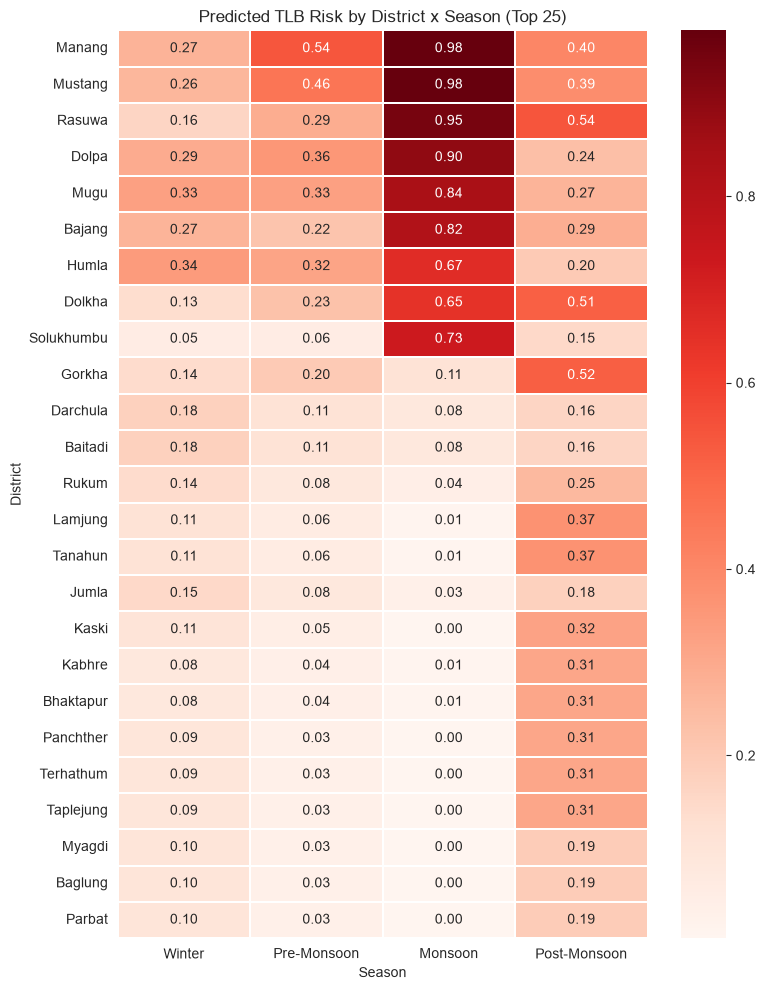

In [46]:
# district x season heatmap for top 25 districts
top25 = dist_risk.head(25)["District"].tolist()
top25_df = risk_df[risk_df["District"].isin(top25)]

risk_pivot = top25_df.pivot_table(index="District", columns="Season", values="Predicted_Risk", aggfunc="mean")
risk_pivot = risk_pivot[["Winter", "Pre-Monsoon", "Monsoon", "Post-Monsoon"]]
risk_pivot = risk_pivot.loc[top25]

plt.figure(figsize=(8, 10))
sns.heatmap(risk_pivot, cmap="Reds", annot=True, fmt=".2f", linewidths=0.3, linecolor="white")
plt.title("Predicted TLB Risk by District x Season (Top 25)")
plt.tight_layout()
plt.savefig("outputs/risk_district_season.png", dpi=150, bbox_inches="tight")
plt.show()

# **Saving the model**

In [47]:
xgb_tuned.get_booster().save_model("outputs/final_model_xgb.json")
joblib.dump({"features": features, "threshold": float(thr_tuned)}, "outputs/final_model_info.joblib")

print("Saved: outputs/final_model_xgb.json, outputs/final_model_info.joblib")

Saved: outputs/final_model_xgb.json, outputs/final_model_info.joblib


## Conclusion

- My label is based on a weather rule (RH > 80% and Tmin < 10 °C), so I am predicting favourable
  weather for TLB for the next day, not the disease itself.
- After fixing the split and the leakage the scores look more realistic. Tuned XGBoost was the best
  on 2016-2019: F1 = 0.744, recall = 0.79, PR-AUC = 0.841, ROC-AUC = 0.988.
- The baseline (tomorrow = today) was already quite good with F1 = 0.717. The models are only a bit
  better in F1, but much better in PR-AUC (0.53 to 0.84), so the probabilities are more useful.
- RF, XGBoost and CatBoost gave almost the same results. Logistic regression and decision tree were
  lower.
- 2019 was harder to predict (F1 = 0.69) than 2016-2018 (0.75-0.79).
- Highest risk is in monsoon in the mountain districts like Manang, Mustang, Rasuwa, Dolpa and Mugu.

**Limitations and what I want to do next:** check the results with real blight records, add elevation
and crop area data, and try predicting 3 or 7 days ahead.